In [1]:
# ======================================================================
# 01 | Business Context and KPI Framework
# ======================================================================

"""
RETAILAI — E-COMMERCE BUSINESS INTELLIGENCE

Business questions
------------------
1. What drives recorded marketplace payment volume?
2. Are growth changes caused by order volume or order value?
3. Which customer segments contribute the most revenue?
4. How does customer retention vary across cohorts?
5. Where do delivery problems and customer dissatisfaction overlap?
6. Which interventions should the business test first?

Metric definitions
------------------
Recorded payment volume:
    Sum of payment_value for eligible orders.

Eligible orders:
    Orders excluding canceled and unavailable statuses.

Average Order Value (AOV):
    Recorded payment volume / eligible orders with payments.

Repeat Purchase Rate:
    Customers with 2+ eligible orders / purchasing customers.

Important:
    Recorded payments are not net revenue, profit, or GMV.
    The historical Olist dataset is not live business data.
"""

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "datasets").exists():
    ROOT = ROOT.parent

DATA = ROOT / "datasets" / "processed"
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110
})

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)

print("RetailAI | Business Intelligence")
print("Project root:", ROOT)
print("Currency: BRL")
print("Analytical framework initialized.")

RetailAI | Business Intelligence
Project root: /Users/adityachaubey/Desktop/RetailAI
Currency: BRL
Analytical framework initialized.


In [2]:
# ======================================================================
# 02 | Data Loading and Quality Contracts
# ======================================================================

required_files = {
    "orders": "orders.parquet",
    "items": "order_items.parquet",
    "payments": "order_payments.parquet",
    "customers": "customers.parquet",
    "products": "products.parquet",
    "reviews": "order_reviews.parquet",
}

datasets = {}

for name, filename in required_files.items():
    path = DATA / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing required dataset: {path}")

    datasets[name] = pd.read_parquet(path)

orders = datasets["orders"].copy()
items = datasets["items"].copy()
payments = datasets["payments"].copy()
customers = datasets["customers"].copy()
products = datasets["products"].copy()
reviews_raw = datasets["reviews"].copy()

segments = pd.read_csv(DATA / "customer_segments.csv")
retention = pd.read_csv(
    DATA / "customer_retention_strategies.csv"
)

def validate_primary_key(frame, key, name):
    assert key in frame.columns, f"{name}: missing {key}"
    assert frame[key].notna().all(), f"{name}: null {key}"
    assert frame[key].is_unique, f"{name}: duplicate {key}"

validate_primary_key(orders, "order_id", "orders")
validate_primary_key(customers, "customer_id", "customers")
validate_primary_key(products, "product_id", "products")
validate_primary_key(
    segments, "customer_unique_id", "segments"
)
validate_primary_key(
    retention, "customer_unique_id", "retention"
)

for frame, name in [
    (items, "items"),
    (payments, "payments")
]:
    assert frame["order_id"].notna().all(), (
        f"{name}: null order_id"
    )

for col in ["price", "freight_value"]:
    items[col] = pd.to_numeric(items[col], errors="coerce")

payments["payment_value"] = pd.to_numeric(
    payments["payment_value"], errors="coerce"
)

assert (items["price"].dropna() >= 0).all()
assert (items["freight_value"].dropna() >= 0).all()
assert (payments["payment_value"].dropna() >= 0).all()

quality = []

for name, frame in datasets.items():
    quality.append({
        "dataset": name,
        "rows": len(frame),
        "columns": frame.shape[1],
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_full_rows": int(frame.duplicated().sum())
    })

quality_report = pd.DataFrame(quality)

display(quality_report)

print("Primary-key and numeric integrity checks passed.")
print("Customer segments:", len(segments))
print("Retention records:", len(retention))

,dataset,rows,columns,missing_cells,duplicate_full_rows
0,orders,99441,8,4908,0
1,items,112650,7,0,0
2,payments,103886,5,0,0
3,customers,99441,5,0,0
4,products,32951,9,2448,0
5,reviews,99224,7,145903,0


Primary-key and numeric integrity checks passed.
Customer segments: 93358
Retention records: 93358


In [3]:
# ======================================================================
# 03 | Order-Level Fact Table and Revenue Reconciliation
# ======================================================================

"""
Critical modeling decision:
Payments and order items are both one-to-many against orders.

Joining them directly creates a many-to-many multiplication.

Solution:
1. Aggregate payments to order_id.
2. Aggregate items to order_id.
3. Join both aggregates to the order dimension.
4. Validate row counts and monetary reconciliation.
"""

payment_agg = (
    payments.groupby("order_id", as_index=False)
    .agg(
        recorded_payment_brl=("payment_value", "sum"),
        payment_records=("payment_value", "size"),
        payment_methods=("payment_type", "nunique")
    )
)

item_agg = (
    items.groupby("order_id", as_index=False)
    .agg(
        merchandise_value_brl=("price", "sum"),
        freight_value_brl=("freight_value", "sum"),
        item_count=("order_item_id", "size"),
        unique_products=("product_id", "nunique"),
        unique_sellers=("seller_id", "nunique")
    )
)

fact = (
    orders
    .merge(
        payment_agg,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        item_agg,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        customers[
            [
                "customer_id",
                "customer_unique_id",
                "customer_state",
                "customer_city"
            ]
        ],
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
)

assert len(fact) == len(orders)
assert fact["order_id"].is_unique

source_payment_total = payments["payment_value"].sum()
fact_payment_total = fact["recorded_payment_brl"].sum()

assert np.isclose(
    source_payment_total,
    fact_payment_total,
    rtol=1e-10
), "Payment reconciliation failed."

fact["purchase_timestamp"] = pd.to_datetime(
    fact["order_purchase_timestamp"], errors="coerce"
)

fact["delivered_timestamp"] = pd.to_datetime(
    fact["order_delivered_customer_date"], errors="coerce"
)

fact["estimated_delivery_timestamp"] = pd.to_datetime(
    fact["order_estimated_delivery_date"], errors="coerce"
)

fact["purchase_month"] = (
    fact["purchase_timestamp"].dt.to_period("M")
)

fact["eligible"] = ~fact["order_status"].isin(
    ["canceled", "unavailable"]
)

eligible = fact.loc[fact["eligible"]].copy()

reconciliation = pd.DataFrame([{
    "source_payment_total_brl": source_payment_total,
    "fact_payment_total_brl": fact_payment_total,
    "difference_brl": (
        source_payment_total - fact_payment_total
    ),
    "source_orders": len(orders),
    "fact_orders": len(fact),
    "eligible_orders": len(eligible),
    "eligible_without_payment": int(
        eligible["recorded_payment_brl"].isna().sum()
    )
}])

display(reconciliation)

print("Order-level fact table successfully validated.")

,source_payment_total_brl,fact_payment_total_brl,difference_brl,source_orders,fact_orders,eligible_orders,eligible_without_payment
0,"16,008,872.12","16,008,872.12",0.00,99441,99441,98207,1


Order-level fact table successfully validated.


,metric,value
0,Recorded Payment Volume (BRL),"15,739,137.01"
1,Eligible Orders,"98,207.00"
2,Purchasing Customers,"94,990.00"
3,Average Payment / Paid Order (BRL),160.27
4,Repeat Purchase Rate (%),3.04
5,Items / Order,1.14


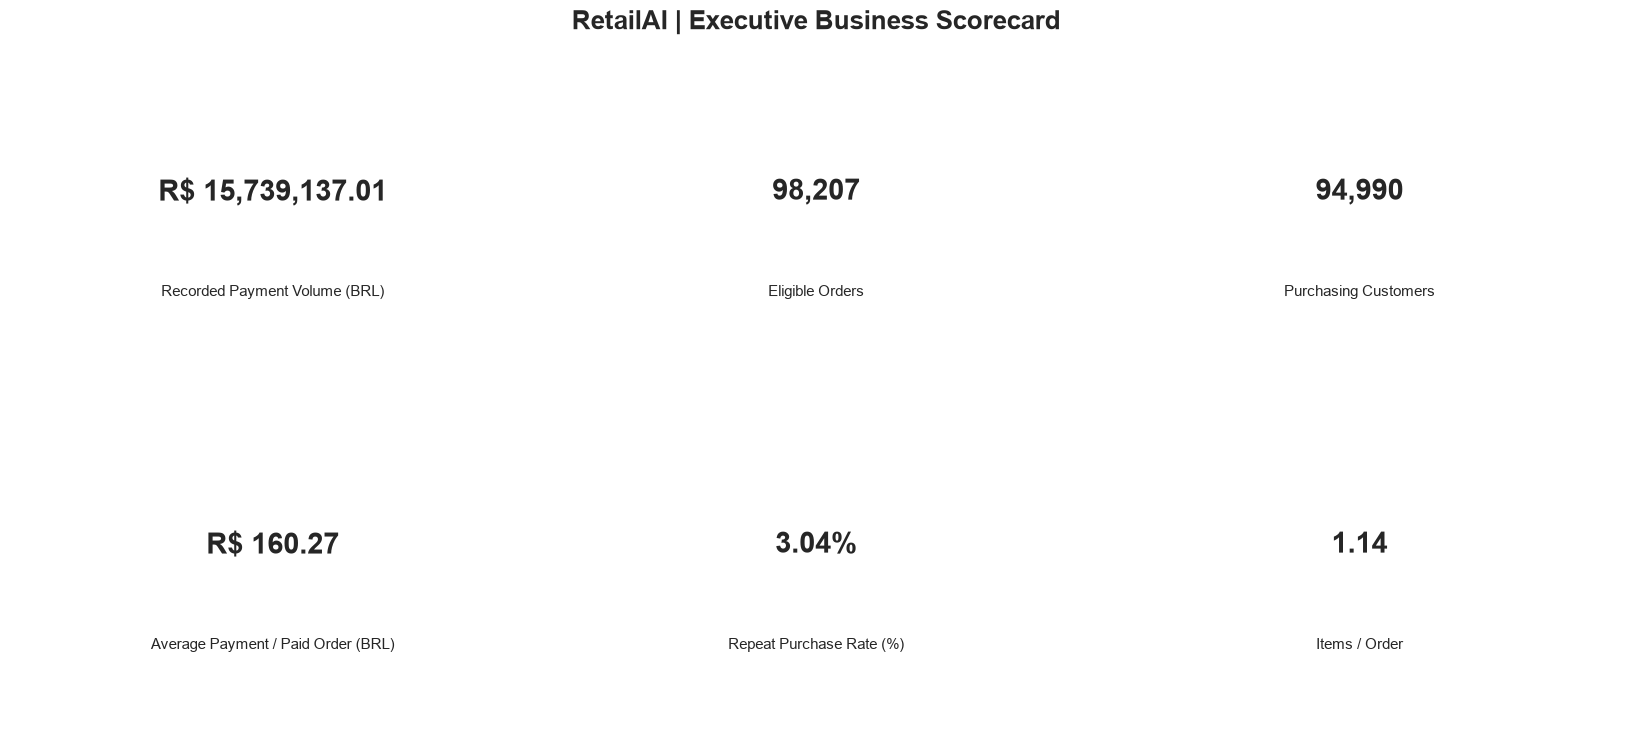

Note: Recorded payment volume is not net profit.


In [4]:
# ======================================================================
# 04 | Executive KPI Scorecard
# ======================================================================

"""
These KPIs form the executive overview of the dashboard.

All revenue-related metrics use the same eligible-order
population to maintain consistent denominators.
"""

customer_frequency = (
    eligible.dropna(subset=["customer_unique_id"])
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

purchasing_customers = len(customer_frequency)

repeat_customers = int(
    customer_frequency.ge(2).sum()
)

recorded_volume = eligible[
    "recorded_payment_brl"
].sum()

paid_order_count = int(
    eligible["recorded_payment_brl"].notna().sum()
)

kpis = {
    "Recorded Payment Volume (BRL)": recorded_volume,
    "Eligible Orders": len(eligible),
    "Purchasing Customers": purchasing_customers,
    "Average Payment / Paid Order (BRL)":
        recorded_volume / paid_order_count
        if paid_order_count else np.nan,
    "Repeat Purchase Rate (%)":
        100 * repeat_customers / purchasing_customers
        if purchasing_customers else np.nan,
    "Items / Order":
        eligible["item_count"].mean()
}

kpi_table = pd.DataFrame(
    [{"metric": k, "value": v} for k, v in kpis.items()]
)

display(kpi_table)

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
axes = axes.flatten()

for ax, (metric, value) in zip(axes, kpis.items()):
    ax.axis("off")

    if "Rate" in metric:
        formatted = f"{value:,.2f}%"
    elif "Volume" in metric or "(BRL)" in metric:
        formatted = f"R$ {value:,.2f}"
    elif "Items" in metric:
        formatted = f"{value:,.2f}"
    else:
        formatted = f"{value:,.0f}"

    ax.text(
        0.5, 0.60, formatted,
        ha="center", va="center",
        fontsize=19, fontweight="bold",
        transform=ax.transAxes
    )

    ax.text(
        0.5, 0.30, metric,
        ha="center", va="center",
        fontsize=10,
        transform=ax.transAxes
    )

plt.suptitle(
    "RetailAI | Executive Business Scorecard",
    fontsize=17, fontweight="bold"
)
plt.tight_layout()
plt.show()

print("Note: Recorded payment volume is not net profit.")

,orders,recorded_volume_brl,paying_orders,customers,average_payment_brl,revenue_mom_pct,order_mom_pct,complete_calendar_month,reliable_mom_comparison,reportable_mom_pct
purchase_month,,,,,,,,,,
2017-10,4547,"764,785.28",4547,4481,168.20,6.64,7.57,True,True,6.64
2017-11,7423,"1,172,639.23",7423,7315,157.97,53.33,63.25,True,True,53.33
2017-12,5620,"861,914.46",5620,5553,153.37,-26.50,-24.29,True,True,-26.50
2018-01,7187,"1,102,639.41",7187,7088,153.42,27.93,27.88,True,True,27.93
2018-02,6625,"979,966.23",6625,6469,147.92,-11.13,-7.82,True,True,-11.13
2018-03,7168,"1,152,736.74",7168,7077,160.82,17.63,8.20,True,True,17.63
2018-04,6919,"1,156,303.91",6919,6863,167.12,0.31,-3.47,True,True,0.31
2018-05,6833,"1,145,748.63",6833,6775,167.68,-0.91,-1.24,True,True,-0.91
2018-06,6145,"1,020,494.29",6145,6106,166.07,-10.93,-10.07,True,True,-10.93


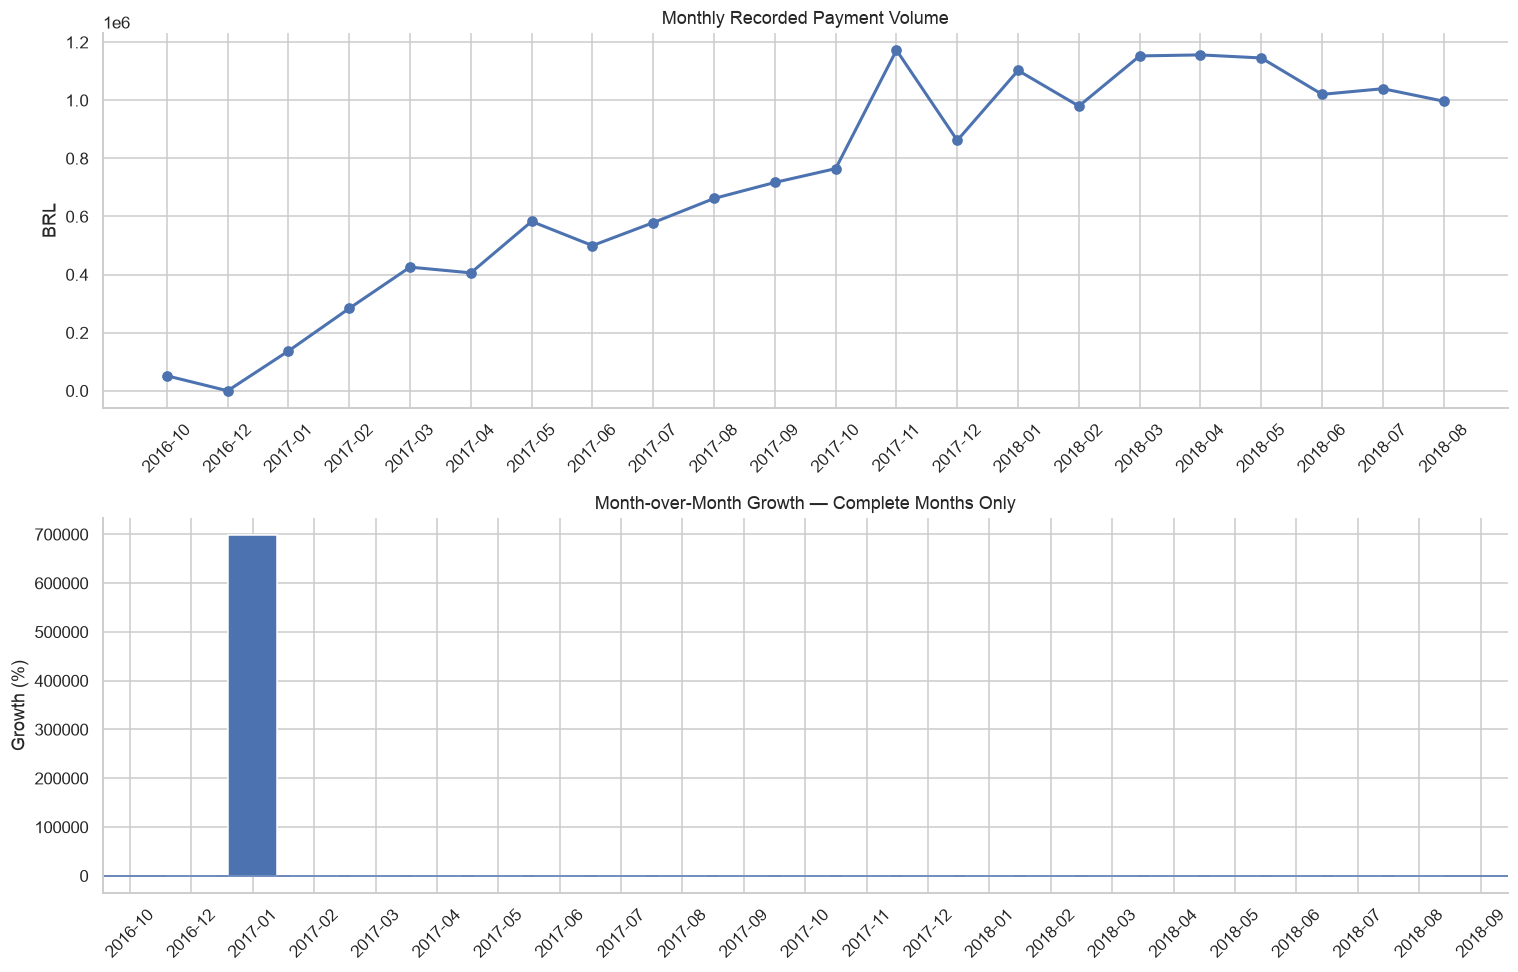

Months with reliable MoM comparisons: 21


In [5]:
# ======================================================================
# 05 | Monthly Revenue Growth and Trend Diagnostics
# ======================================================================

"""
Monthly business performance.

Exclude partial boundary months from growth interpretation.
Keep them visible in the raw monthly table.
"""

monthly = (
    eligible.dropna(subset=["purchase_timestamp"])
    .groupby("purchase_month")
    .agg(
        orders=("order_id", "nunique"),
        recorded_volume_brl=(
            "recorded_payment_brl", "sum"
        ),
        paying_orders=(
            "recorded_payment_brl", "count"
        ),
        customers=("customer_unique_id", "nunique")
    )
    .sort_index()
)

monthly["average_payment_brl"] = (
    monthly["recorded_volume_brl"]
    / monthly["paying_orders"].replace(0, np.nan)
)

monthly["revenue_mom_pct"] = (
    monthly["recorded_volume_brl"].pct_change() * 100
)

monthly["order_mom_pct"] = (
    monthly["orders"].pct_change() * 100
)

# A month is considered fully observable only when
# the source date range covers its first and last day.
min_date = eligible["purchase_timestamp"].min()
max_date = eligible["purchase_timestamp"].max()

monthly["complete_calendar_month"] = [
    (
        period.start_time >= min_date.normalize()
        and period.end_time.normalize()
        <= max_date.normalize()
    )
    for period in monthly.index
]

monthly["reliable_mom_comparison"] = (
    monthly["complete_calendar_month"]
    & monthly["complete_calendar_month"].shift(
        1, fill_value=False
    )
)

monthly["reportable_mom_pct"] = (
    monthly["revenue_mom_pct"].where(
        monthly["reliable_mom_comparison"]
    )
)

display(monthly.tail(12))

plot_monthly = monthly.loc[
    monthly["complete_calendar_month"]
]

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

axes[0].plot(
    plot_monthly.index.astype(str),
    plot_monthly["recorded_volume_brl"],
    marker="o", linewidth=2
)
axes[0].set_title("Monthly Recorded Payment Volume")
axes[0].set_ylabel("BRL")
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(
    monthly.index.astype(str),
    monthly["reportable_mom_pct"]
)
axes[1].axhline(0, linewidth=1)
axes[1].set_title(
    "Month-over-Month Growth — Complete Months Only"
)
axes[1].set_ylabel("Growth (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

print(
    "Months with reliable MoM comparisons:",
    int(monthly["reliable_mom_comparison"].sum())
)

,actual_change_brl,order_volume_effect_brl,order_value_effect_brl,interaction_effect_brl
purchase_month,,,,
2017-11,"407,853.95","483,730.47","-46,478.59","-29,397.94"
2017-12,"-310,724.77","-284,826.69","-34,206.66","8,308.58"
2018-01,"240,724.95","240,323.84",313.66,87.46
2018-02,"-122,673.18","-86,222.81","-39,542.46","3,092.09"
2018-03,"172,770.51","80,320.25","85,446.84","7,003.42"
2018-04,"3,567.17","-40,043.45","45,180.07","-1,569.45"
2018-05,"-10,555.28","-14,372.33","3,865.09",-48.04
2018-06,"-125,254.34","-115,362.95","-10,998.84","1,107.45"
2018-07,"19,385.87","14,614.08","4,704.42",67.37


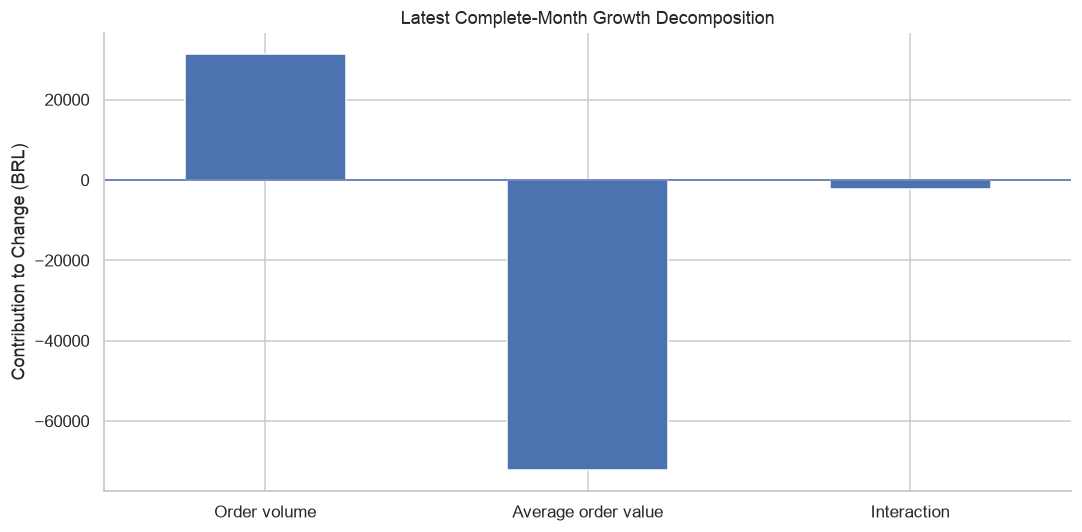

Exact growth decomposition validated.


In [6]:
# ======================================================================
# 06 | Growth Decomposition: Order Volume vs Order Value
# ======================================================================

"""
Business identity:

Recorded payment volume
    = Paying order count × Average payment per paying order

Exact period-over-period decomposition:

Change in volume
    = Change in orders × Previous AOV
    + Change in AOV × Previous orders
    + Interaction term

The interaction term is retained to avoid attribution errors.
"""

growth = monthly[
    ["paying_orders", "average_payment_brl",
     "recorded_volume_brl", "complete_calendar_month"]
].copy()

growth["previous_orders"] = growth[
    "paying_orders"
].shift(1)

growth["previous_aov"] = growth[
    "average_payment_brl"
].shift(1)

growth["order_volume_effect_brl"] = (
    (growth["paying_orders"] - growth["previous_orders"])
    * growth["previous_aov"]
)

growth["order_value_effect_brl"] = (
    growth["previous_orders"]
    * (
        growth["average_payment_brl"]
        - growth["previous_aov"]
    )
)

growth["interaction_effect_brl"] = (
    (growth["paying_orders"] - growth["previous_orders"])
    * (
        growth["average_payment_brl"]
        - growth["previous_aov"]
    )
)

growth["actual_change_brl"] = (
    growth["recorded_volume_brl"].diff()
)

growth["explained_change_brl"] = (
    growth["order_volume_effect_brl"]
    + growth["order_value_effect_brl"]
    + growth["interaction_effect_brl"]
)

growth["valid_comparison"] = (
    growth["complete_calendar_month"]
    & growth["complete_calendar_month"].shift(
        1, fill_value=False
    )
    & growth["average_payment_brl"].notna()
    & growth["previous_aov"].notna()
)

valid_growth = growth.loc[
    growth["valid_comparison"]
].copy()

assert np.allclose(
    valid_growth["actual_change_brl"],
    valid_growth["explained_change_brl"],
    atol=0.01
), "Growth decomposition does not reconcile."

display(
    valid_growth[
        [
            "actual_change_brl",
            "order_volume_effect_brl",
            "order_value_effect_brl",
            "interaction_effect_brl"
        ]
    ].tail(10)
)

if not valid_growth.empty:
    last = valid_growth.iloc[-1]

    effects = pd.Series({
        "Order volume": last["order_volume_effect_brl"],
        "Average order value": last["order_value_effect_brl"],
        "Interaction": last["interaction_effect_brl"]
    })

    fig, ax = plt.subplots(figsize=(10, 5))
    effects.plot.bar(ax=ax)

    ax.axhline(0, linewidth=1)
    ax.set_title(
        "Latest Complete-Month Growth Decomposition"
    )
    ax.set_ylabel("Contribution to Change (BRL)")
    ax.tick_params(axis="x", rotation=0)

    plt.tight_layout()
    plt.show()

print("Exact growth decomposition validated.")

,customer_segment,customers,orders,recorded_volume_brl,avg_customer_spend_brl,median_customer_spend_brl,repeat_customers,revenue_share_pct,repeat_rate_pct
0,One-Time / Low-Engagement Customers,90557,90639,"14,569,407.77",160.89,105.56,81,92.57,0.09
1,Repeat High-Value Customers,2801,5930,"865,453.50",308.98,226.05,2801,5.50,100.00
2,Unsegmented,1632,1638,"304,275.74",186.44,114.94,6,1.93,0.37


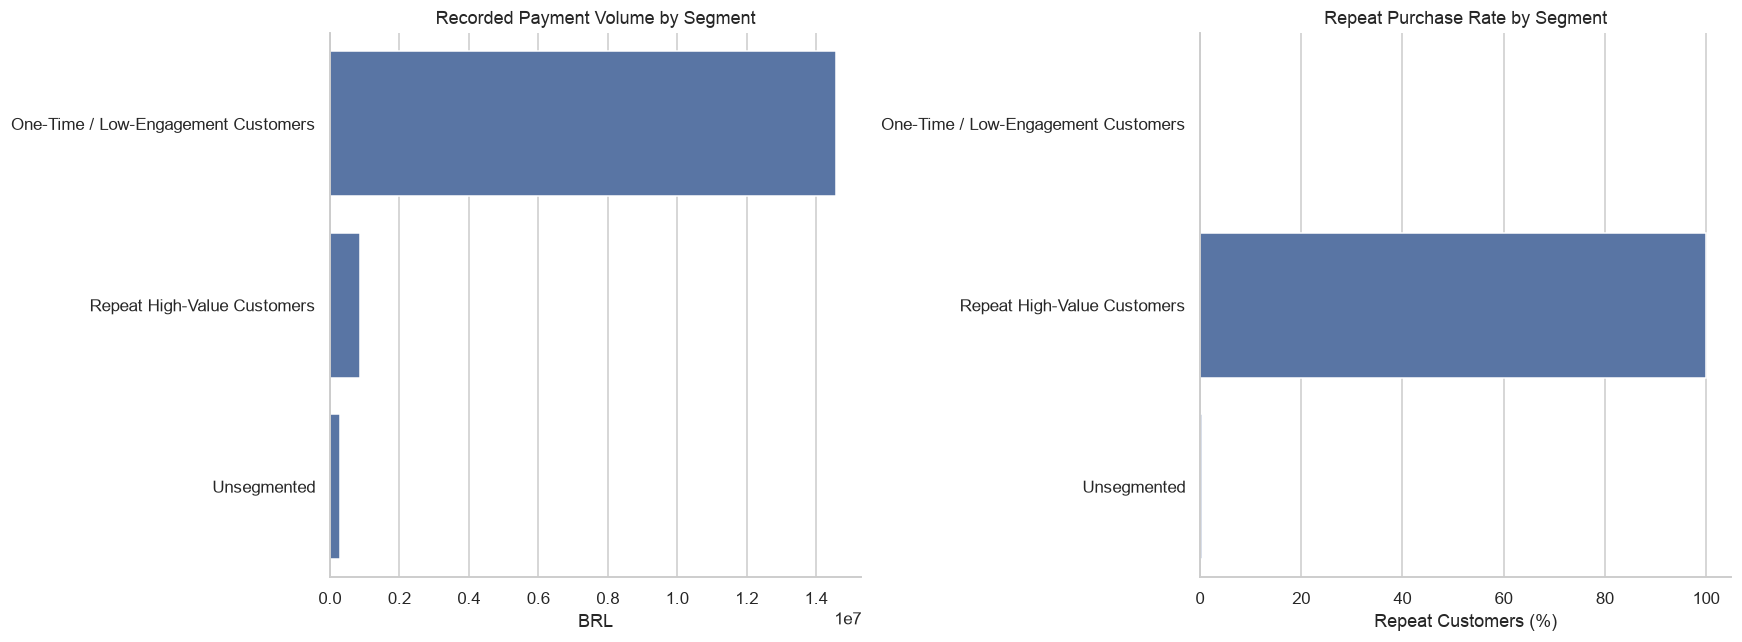

Top 10% customer revenue concentration: 38.29%
Unsegmented customers: 1632
Business interpretation: prioritize segments based on both value and repeat behavior, not revenue alone.


In [7]:
# ======================================================================
# 07 | Customer Segment Economics and Revenue Concentration
# ======================================================================

"""
Customer segmentation should answer:

- Which segments generate the most recorded volume?
- Which segments have the highest average customer value?
- Is revenue concentrated among a small number of customers?
- Are existing RFM labels consistent with observed spending?

Important:
The segmentation dataset is derived from historical orders.
This is descriptive analysis, not out-of-sample prediction.
"""

customer_spend = (
    eligible.dropna(subset=["customer_unique_id"])
    .groupby("customer_unique_id", as_index=False)
    .agg(
        observed_orders=("order_id", "nunique"),
        observed_payment_brl=(
            "recorded_payment_brl", "sum"
        )
    )
)

customer_spend = customer_spend.merge(
    segments[
        [
            "customer_unique_id",
            "customer_segment",
            "RFM_score",
            "cluster"
        ]
    ],
    on="customer_unique_id",
    how="left",
    validate="one_to_one"
)

customer_spend["customer_segment"] = (
    customer_spend["customer_segment"]
    .fillna("Unsegmented")
)

segment_summary = (
    customer_spend.groupby("customer_segment")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("observed_orders", "sum"),
        recorded_volume_brl=(
            "observed_payment_brl", "sum"
        ),
        avg_customer_spend_brl=(
            "observed_payment_brl", "mean"
        ),
        median_customer_spend_brl=(
            "observed_payment_brl", "median"
        ),
        repeat_customers=(
            "observed_orders",
            lambda s: int((s >= 2).sum())
        )
    )
    .reset_index()
)

segment_summary["revenue_share_pct"] = (
    100 * segment_summary["recorded_volume_brl"]
    / segment_summary["recorded_volume_brl"].sum()
)

segment_summary["repeat_rate_pct"] = (
    100 * segment_summary["repeat_customers"]
    / segment_summary["customers"]
)

segment_summary = segment_summary.sort_values(
    "recorded_volume_brl", ascending=False
)

assert (
    segment_summary["customers"].sum()
    == len(customer_spend)
)

assert np.isclose(
    segment_summary["recorded_volume_brl"].sum(),
    customer_spend["observed_payment_brl"].sum()
)

display(segment_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=segment_summary,
    x="recorded_volume_brl",
    y="customer_segment",
    ax=axes[0]
)

axes[0].set_title("Recorded Payment Volume by Segment")
axes[0].set_xlabel("BRL")
axes[0].set_ylabel("")

sns.barplot(
    data=segment_summary,
    x="repeat_rate_pct",
    y="customer_segment",
    ax=axes[1]
)

axes[1].set_title("Repeat Purchase Rate by Segment")
axes[1].set_xlabel("Repeat Customers (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

# Revenue concentration analysis
ranked_customers = customer_spend.sort_values(
    "observed_payment_brl", ascending=False
)

top_10_count = max(
    1, int(np.ceil(len(ranked_customers) * 0.10))
)

top_10_share = (
    100
    * ranked_customers.head(top_10_count)[
        "observed_payment_brl"
    ].sum()
    / ranked_customers["observed_payment_brl"].sum()
)

print(
    f"Top 10% customer revenue concentration: "
    f"{top_10_share:.2f}%"
)

print(
    "Unsegmented customers:",
    customer_spend["customer_segment"]
    .eq("Unsegmented").sum()
)

print(
    "Business interpretation: prioritize segments based "
    "on both value and repeat behavior, not revenue alone."
)

months_since_first,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2016-09,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2016-10,100.00,0.00,0.00,0.00,0.00,0.00,0.34,0.00,0.00,0.34,0.00,0.34
2016-12,100.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
2017-01,100.00,0.40,0.27,0.13,0.40,0.13,0.40,0.13,0.13,0.00,0.40,0.13
2017-02,100.00,0.24,0.30,0.12,0.41,0.12,0.24,0.18,0.12,0.18,0.12,0.30
2017-03,100.00,0.51,0.35,0.39,0.35,0.16,0.16,0.31,0.35,0.08,0.39,0.12
2017-04,100.00,0.60,0.22,0.17,0.30,0.26,0.34,0.30,0.30,0.17,0.26,0.09
2017-05,100.00,0.48,0.48,0.40,0.31,0.34,0.42,0.14,0.25,0.25,0.25,0.34
2017-06,100.00,0.45,0.35,0.39,0.26,0.39,0.35,0.23,0.13,0.23,0.32,0.32


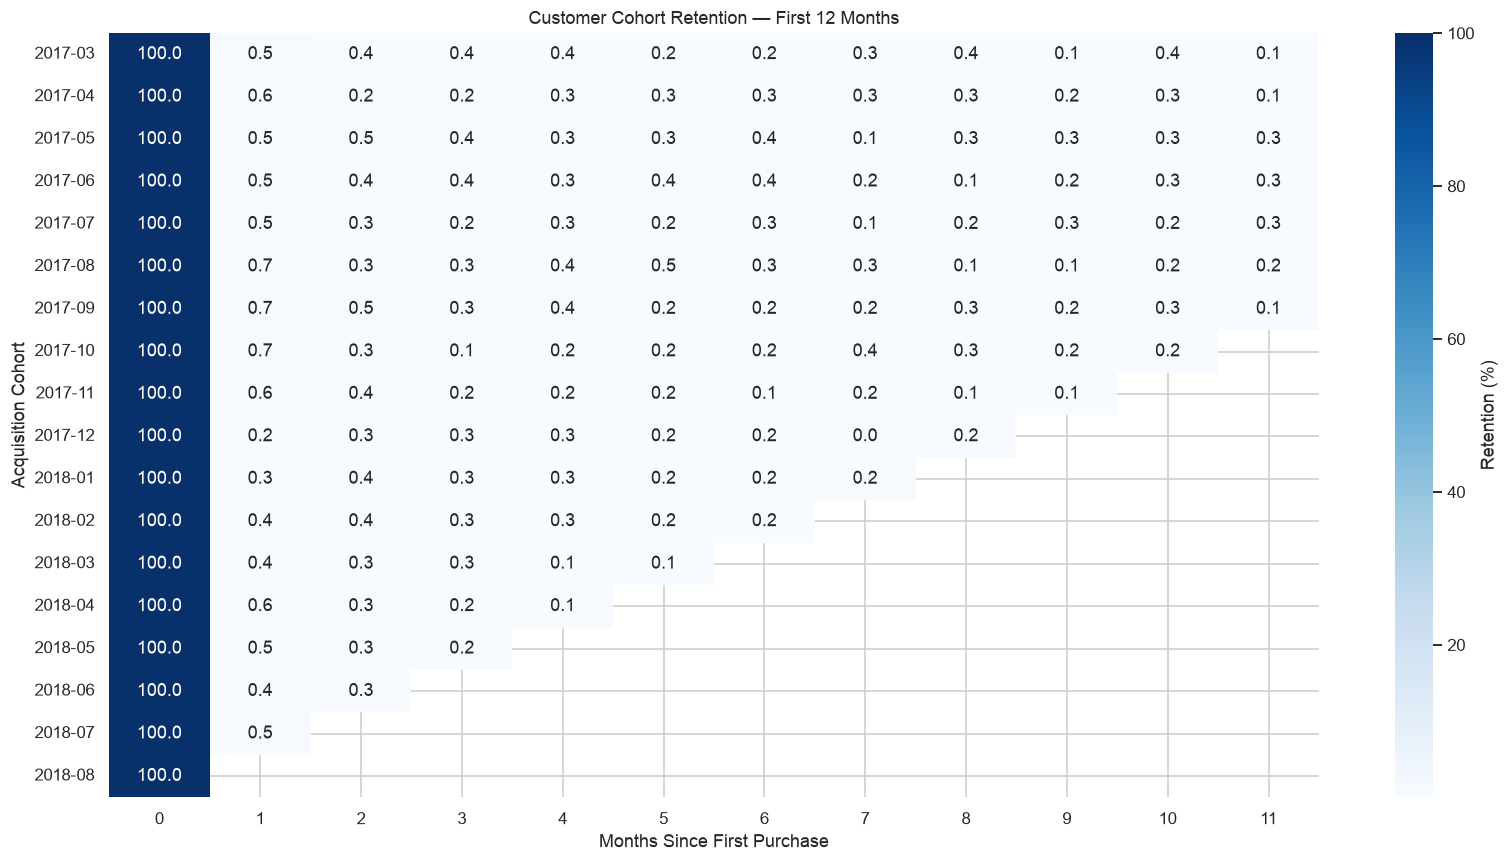

Cohort sizes: 23
Last fully observed month: 2018-08
Interpretation: same-month repeat activity is included in month zero; future months are censored.


In [8]:
# ========================================================================
# 08 | Customer Cohort Retention and Observation Windows
# ========================================================================

"""
Business question:
Do customers return after their first purchase?

A cohort is defined by the customer's first observed
eligible purchase month.

We avoid counting future, unobservable months as churn.
"""

cohort_orders = eligible.dropna(
    subset=["customer_unique_id", "purchase_timestamp"]
).copy()

cohort_orders["order_month"] = (
    cohort_orders["purchase_timestamp"].dt.to_period("M")
)

first_purchase = (
    cohort_orders.groupby("customer_unique_id")["order_month"]
    .min()
    .rename("cohort_month")
)

cohort_orders = cohort_orders.join(
    first_purchase, on="customer_unique_id"
)

cohort_orders["months_since_first"] = (
    (cohort_orders["order_month"].dt.year -
     cohort_orders["cohort_month"].dt.year) * 12
    + cohort_orders["order_month"].dt.month
    - cohort_orders["cohort_month"].dt.month
)

assert cohort_orders["months_since_first"].ge(0).all()

cohort_sizes = (
    cohort_orders.groupby("cohort_month")["customer_unique_id"]
    .nunique()
)

cohort_active = (
    cohort_orders.groupby(
        ["cohort_month", "months_since_first"]
    )["customer_unique_id"]
    .nunique()
    .unstack(fill_value=0)
)

cohort_retention = cohort_active.div(
    cohort_sizes, axis=0
)

# Months after the last fully observed calendar month
# must be missing, not zero retention.
observation_end = (
    cohort_orders["order_month"].max() - 1
)

for cohort in cohort_retention.index:
    for age in cohort_retention.columns:
        if cohort + int(age) > observation_end:
            cohort_retention.loc[cohort, age] = np.nan

# Limit visualization to the first 12 months.
retention_12 = cohort_retention.reindex(
    columns=range(12)
)

display(
    (retention_12.head(12) * 100).round(2)
)

plt.figure(figsize=(15, 8))
sns.heatmap(
    retention_12.tail(18) * 100,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    mask=retention_12.tail(18).isna(),
    cbar_kws={"label": "Retention (%)"}
)

plt.title("Customer Cohort Retention — First 12 Months")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Acquisition Cohort")
plt.tight_layout()
plt.show()

print("Cohort sizes:", len(cohort_sizes))
print("Last fully observed month:", observation_end)
print(
    "Interpretation: same-month repeat activity is "
    "included in month zero; future months are censored."
)

,category,merchandise_brl,freight_brl,units,orders,products,sellers,merchandise_share_pct,avg_item_price_brl
43,health_beauty,"1,255,695.13","181,970.65",9634,8800,2430,489,9.31,130.34
73,watches_gifts,"1,198,185.21","100,107.26",5970,5604,1322,98,8.88,200.70
7,bed_bath_table,"1,035,964.06","204,422.07",11097,9399,3022,195,7.68,93.36
67,sports_leisure,"979,740.92","167,503.71",8590,7673,2850,477,7.26,114.06
15,computers_accessories,"904,322.02","146,619.56",7781,6654,1630,285,6.70,116.22
39,furniture_decor,"727,465.05","172,160.99",8298,6425,2641,366,5.39,87.67
49,housewares,"626,825.80","145,209.34",6915,5847,2314,463,4.65,90.65
20,cool_stuff,"620,770.49","83,315.75",3779,3616,783,263,4.60,164.27
5,auto,"586,585.73","92,020.91",4204,3872,1882,374,4.35,139.53
42,garden_tools,"481,009.94","98,515.26",4328,3505,748,235,3.56,111.14


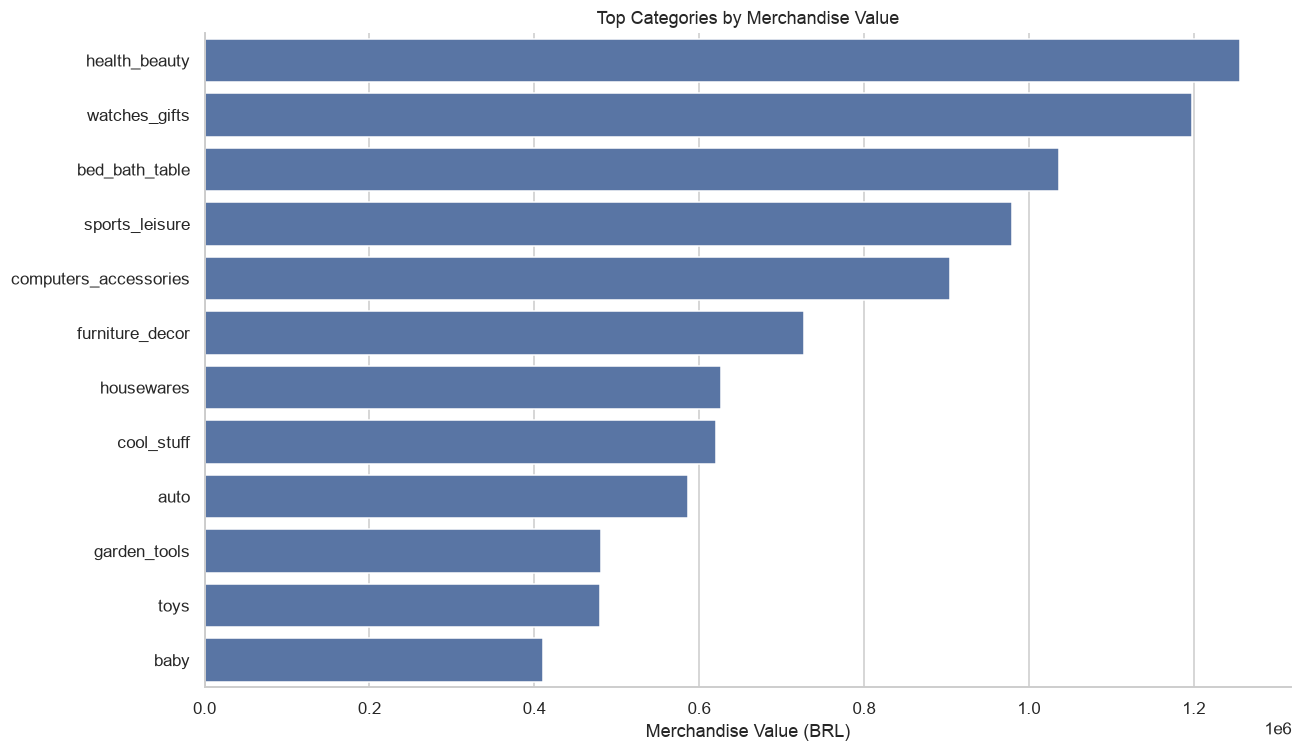

Top 10 category concentration: 62.37%


In [9]:
# ========================================================================
# 09 | Category Economics and Revenue Concentration
# ========================================================================

"""
Category performance is based on merchandise value.

We do not join payment totals to individual item rows,
because that would duplicate order-level payments.

Category sales are not profit: product cost, refunds,
fees and fulfillment costs are unavailable.
"""

category_items = items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

translation_path = ROOT / "datasets/raw/product_category_name_translation.csv"

if translation_path.exists():
    translation = pd.read_csv(translation_path)

    assert translation[
        "product_category_name"
    ].is_unique, "Translation table contains duplicate keys."

    category_items = category_items.merge(
        translation,
        on="product_category_name",
        how="left",
        validate="many_to_one"
    )

    category_items["category"] = (
        category_items["product_category_name_english"]
        .fillna(category_items["product_category_name"])
    )
else:
    category_items["category"] = (
        category_items["product_category_name"]
    )

category_items["category"] = (
    category_items["category"].fillna("unknown")
)

eligible_order_ids = set(eligible["order_id"])

category_items = category_items.loc[
    category_items["order_id"].isin(eligible_order_ids)
].copy()

category_kpis = (
    category_items.groupby("category", as_index=False)
    .agg(
        merchandise_brl=("price", "sum"),
        freight_brl=("freight_value", "sum"),
        units=("order_item_id", "size"),
        orders=("order_id", "nunique"),
        products=("product_id", "nunique"),
        sellers=("seller_id", "nunique")
    )
)

category_kpis["merchandise_share_pct"] = (
    100 * category_kpis["merchandise_brl"]
    / category_kpis["merchandise_brl"].sum()
)

category_kpis["avg_item_price_brl"] = (
    category_kpis["merchandise_brl"]
    / category_kpis["units"]
)

category_kpis = category_kpis.sort_values(
    "merchandise_brl", ascending=False
)

assert np.isclose(
    category_kpis["merchandise_brl"].sum(),
    category_items["price"].sum()
)

display(category_kpis.head(15))

plt.figure(figsize=(12, 7))
sns.barplot(
    data=category_kpis.head(12),
    x="merchandise_brl",
    y="category"
)
plt.title("Top Categories by Merchandise Value")
plt.xlabel("Merchandise Value (BRL)")
plt.ylabel("")
plt.tight_layout()
plt.show()

top_10_category_share = (
    category_kpis.head(10)["merchandise_brl"].sum()
    / category_kpis["merchandise_brl"].sum()
    * 100
)

print(
    f"Top 10 category concentration: "
    f"{top_10_category_share:.2f}%"
)

,customer_state,orders,customers,recorded_payment_brl,paid_orders,aov_brl,revenue_share_pct
25,SP,41127,39749,"5,878,935.99",41126,142.95,37.35
18,RJ,12698,12242,"2,115,994.28",12698,166.64,13.44
10,MG,11496,11134,"1,843,460.37",11496,160.36,11.71
22,RS,5417,5234,"877,803.80",5417,162.05,5.58
17,PR,4983,4825,"794,653.20",4983,159.47,5.05
23,SC,3600,3502,"608,180.51",3600,168.94,3.86
4,BA,3344,3244,"607,041.45",3344,181.53,3.86
6,DF,2121,2058,"351,487.63",2121,165.72,2.23
8,GO,1998,1934,"340,626.24",1998,170.48,2.16
7,ES,2018,1950,"323,105.75",2018,160.11,2.05


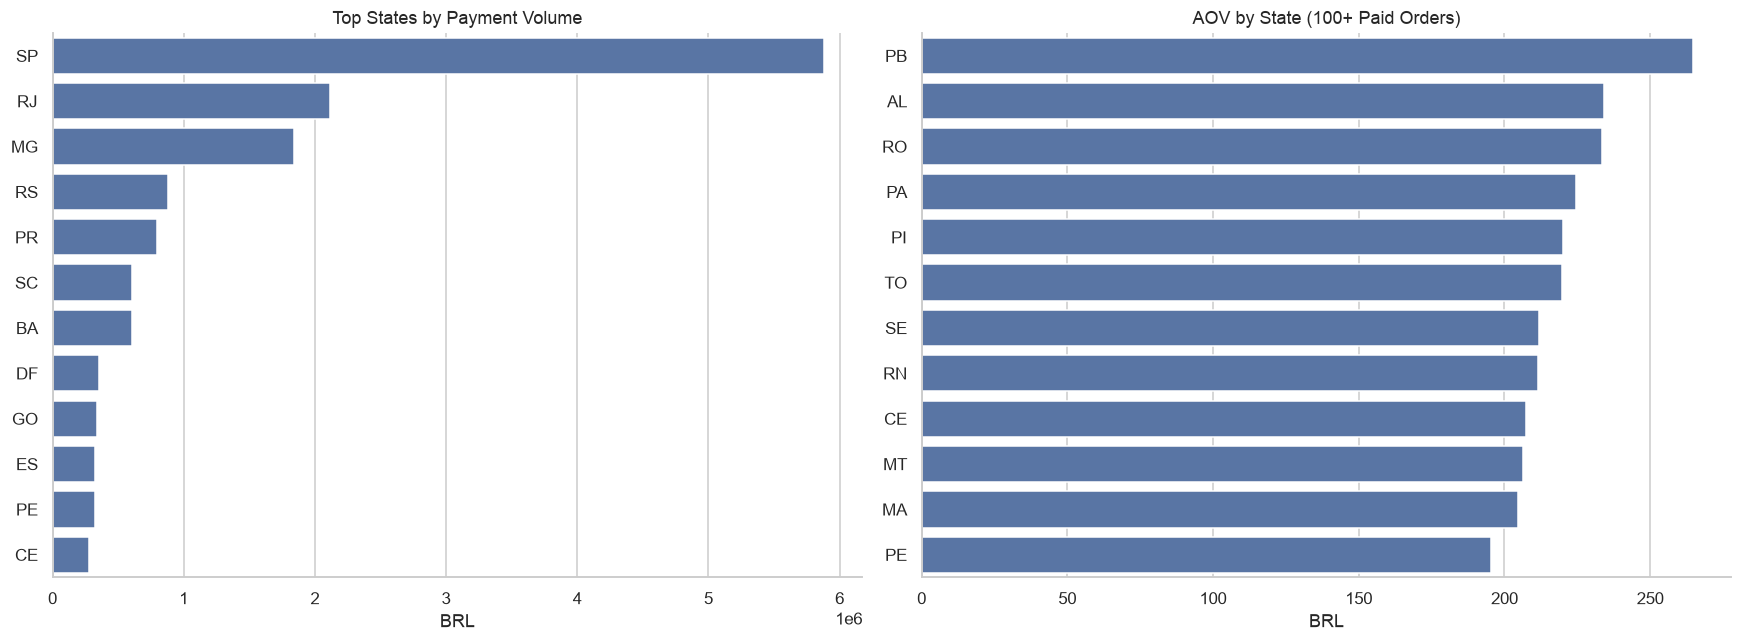

In [10]:
# ========================================================================
# 10 | Geographic Business Performance
# ========================================================================

"""
Business question:
Where are order volume and customer value concentrated?

Customer geography is taken from the customer table.
This represents customer location, not seller location.
"""

state_kpis = (
    eligible.groupby("customer_state", dropna=False)
    .agg(
        orders=("order_id", "nunique"),
        customers=("customer_unique_id", "nunique"),
        recorded_payment_brl=(
            "recorded_payment_brl", "sum"
        ),
        paid_orders=("recorded_payment_brl", "count")
    )
    .reset_index()
)

state_kpis["aov_brl"] = (
    state_kpis["recorded_payment_brl"]
    / state_kpis["paid_orders"].replace(0, np.nan)
)

state_kpis["revenue_share_pct"] = (
    100 * state_kpis["recorded_payment_brl"]
    / state_kpis["recorded_payment_brl"].sum()
)

state_kpis = state_kpis.sort_values(
    "recorded_payment_brl", ascending=False
)

assert state_kpis["orders"].sum() == len(eligible)

display(state_kpis.head(15))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=state_kpis.head(12),
    x="recorded_payment_brl",
    y="customer_state",
    ax=axes[0]
)
axes[0].set_title("Top States by Payment Volume")
axes[0].set_xlabel("BRL")
axes[0].set_ylabel("")

# Minimum sample size to avoid ranking tiny markets by AOV.
large_states = state_kpis.loc[
    state_kpis["paid_orders"] >= 100
].sort_values("aov_brl", ascending=False)

sns.barplot(
    data=large_states.head(12),
    x="aov_brl",
    y="customer_state",
    ax=axes[1]
)
axes[1].set_title("AOV by State (100+ Paid Orders)")
axes[1].set_xlabel("BRL")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

,late_delivery,orders,avg_rating,low_rating_rate,avg_delivery_days,median_delay_days
0,False,88163,4.29,0.09,10.88,-12.32
1,True,7661,2.57,0.54,31.38,5.78


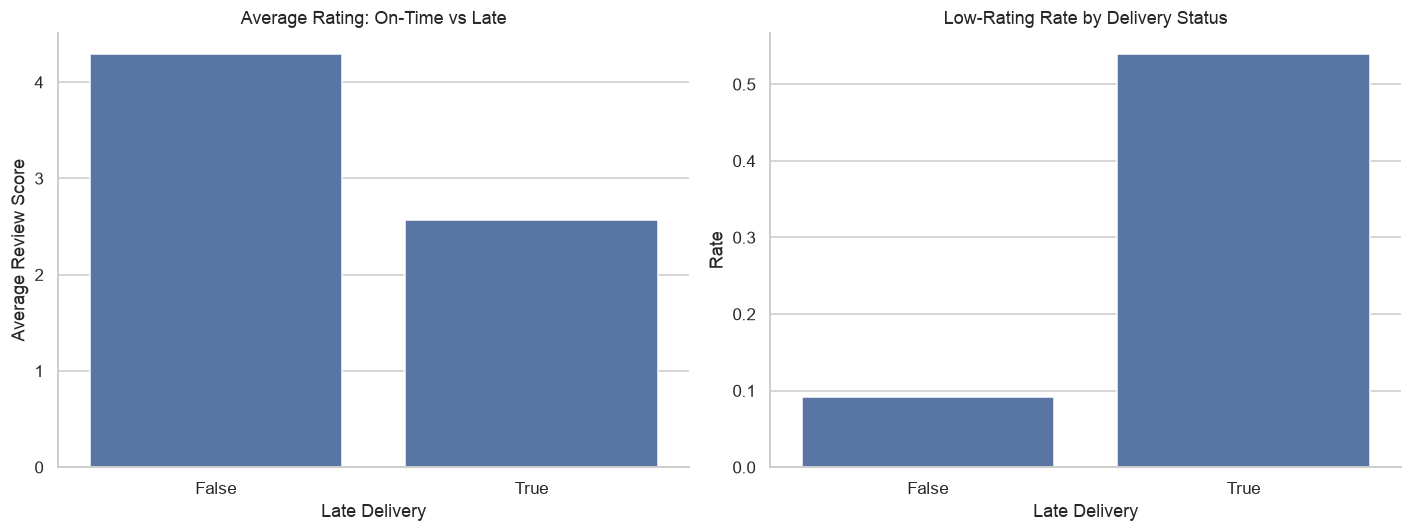

Delivered orders with usable ratings: 95824
Association does not establish causality.


In [11]:
# ========================================================================
# 11 | Delivery Performance and Satisfaction
# ========================================================================

"""
Business question:
Are late deliveries associated with lower customer ratings?

Delivery performance is measured only for orders with
actual and estimated delivery timestamps.

Review ratings are aggregated to order level to avoid
duplicating orders with multiple review records.
"""

delivery = eligible.loc[
    eligible["order_status"].eq("delivered")
].copy()

delivery["delivery_delay_days"] = (
    (
        delivery["delivered_timestamp"]
        - delivery["estimated_delivery_timestamp"]
    ).dt.total_seconds() / 86400
)

delivery["actual_delivery_days"] = (
    (
        delivery["delivered_timestamp"]
        - delivery["purchase_timestamp"]
    ).dt.total_seconds() / 86400
)

delivery = delivery.dropna(
    subset=[
        "delivery_delay_days",
        "actual_delivery_days"
    ]
)

delivery = delivery.loc[
    delivery["actual_delivery_days"] >= 0
].copy()

delivery["late_delivery"] = (
    delivery["delivery_delay_days"] > 0
)

# All available ratings, including reviews without text.
rating_order = (
    reviews_raw.dropna(subset=["review_score"])
    .groupby("order_id", as_index=False)
    .agg(
        average_review_score=("review_score", "mean"),
        review_records=("review_score", "size")
    )
)

delivery = delivery.merge(
    rating_order,
    on="order_id",
    how="left",
    validate="one_to_one"
)

delivery["low_rating"] = (
    delivery["average_review_score"] <= 2
)

rated_delivery = delivery.dropna(
    subset=["average_review_score"]
).copy()

delivery_kpis = (
    rated_delivery.groupby("late_delivery")
    .agg(
        orders=("order_id", "nunique"),
        avg_rating=("average_review_score", "mean"),
        low_rating_rate=("low_rating", "mean"),
        avg_delivery_days=("actual_delivery_days", "mean"),
        median_delay_days=("delivery_delay_days", "median")
    )
    .reset_index()
)

display(delivery_kpis)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=delivery_kpis,
    x="late_delivery",
    y="avg_rating",
    ax=axes[0]
)
axes[0].set_title("Average Rating: On-Time vs Late")
axes[0].set_xlabel("Late Delivery")
axes[0].set_ylabel("Average Review Score")

sns.barplot(
    data=delivery_kpis,
    x="late_delivery",
    y="low_rating_rate",
    ax=axes[1]
)
axes[1].set_title("Low-Rating Rate by Delivery Status")
axes[1].set_xlabel("Late Delivery")
axes[1].set_ylabel("Rate")

plt.tight_layout()
plt.show()

print("Delivered orders with usable ratings:", len(rated_delivery))
print("Association does not establish causality.")

,sentiment,reviews,avg_rating,avg_confidence,disagreement_rate
0,negative,11772,1.61,0.87,0.19
1,neutral,8544,3.81,0.71,0.81
2,positive,22371,4.76,0.82,0.04


Order-level text coverage: 43.11%


,complaint_type,matched_reviews
0,complaint_delivery,8364
1,complaint_wrong_or_missing_item,1566
2,complaint_product_quality,1368
3,complaint_refund_return,1164
4,complaint_service,1114
5,complaint_packaging,548


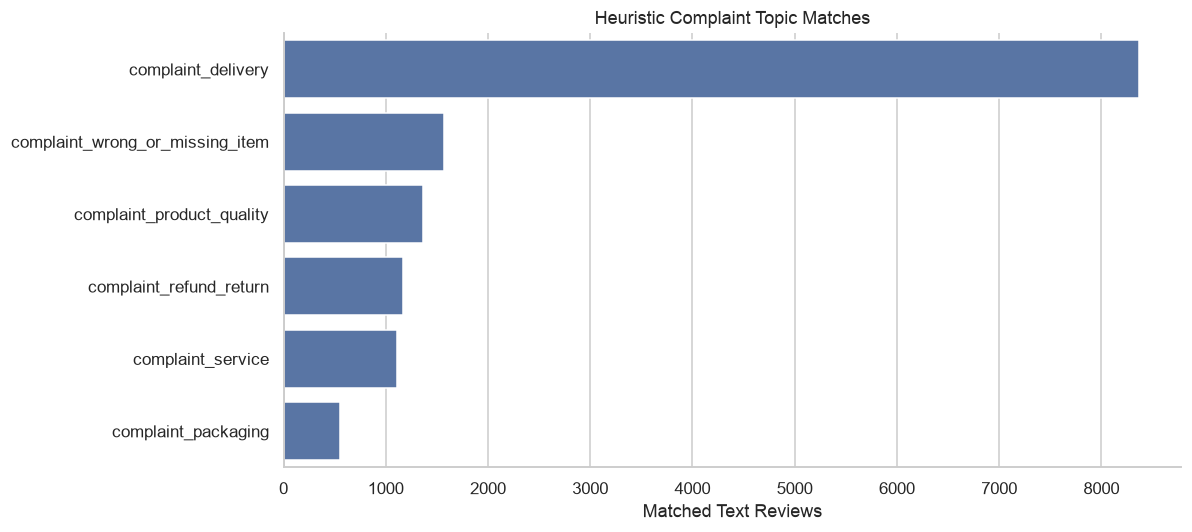

Keyword matches may include negations or praise and require manual precision checks.


In [12]:
# ========================================================================
# 12 | NLP Review Intelligence and Model Diagnostics
# ========================================================================

"""
NLP results were generated in Notebook 04.

Quality safeguards:
- Compare predicted sentiment with review ratings.
- Measure text coverage.
- Do not treat keyword matches as verified complaints.
- Do not infer seller-wide performance from text reviews alone.
"""

nlp = pd.read_parquet(
    DATA / "review_product_intelligence.parquet"
)

assert {
    "review_id", "order_id", "sentiment",
    "review_score", "sentiment_confidence"
}.issubset(nlp.columns)

nlp = nlp.drop_duplicates(
    ["review_id", "order_id"]
).copy()

nlp["rating_polarity"] = np.select(
    [
        nlp["review_score"].le(2),
        nlp["review_score"].ge(4)
    ],
    ["negative", "positive"],
    default="neutral"
)

nlp["sentiment_disagreement"] = (
    nlp["sentiment"] != nlp["rating_polarity"]
)

nlp_summary = (
    nlp.groupby("sentiment")
    .agg(
        reviews=("review_id", "size"),
        avg_rating=("review_score", "mean"),
        avg_confidence=("sentiment_confidence", "mean"),
        disagreement_rate=(
            "sentiment_disagreement", "mean"
        )
    )
    .reset_index()
)

text_coverage = (
    nlp["order_id"].nunique()
    / reviews_raw["order_id"].nunique()
)

display(nlp_summary)

print(f"Order-level text coverage: {text_coverage:.2%}")

complaint_columns = [
    col for col in nlp.columns
    if col.startswith("complaint_")
]

complaint_counts = (
    nlp[complaint_columns]
    .fillna(False)
    .astype(bool)
    .sum()
    .sort_values(ascending=False)
)

complaint_summary = complaint_counts.rename_axis(
    "complaint_type"
).reset_index(name="matched_reviews")

display(complaint_summary)

plt.figure(figsize=(11, 5))
sns.barplot(
    data=complaint_summary,
    x="matched_reviews",
    y="complaint_type"
)
plt.title("Heuristic Complaint Topic Matches")
plt.xlabel("Matched Text Reviews")
plt.ylabel("")
plt.tight_layout()
plt.show()

print(
    "Warning: Rating-sentiment disagreement is a "
    "diagnostic proxy, not validated model accuracy."
)
print(
    "Keyword matches may include negations or praise "
    "and require manual precision checks."
)

In [13]:
# ========================================================================
# 13 | Hypothesis Test: Late Delivery and Low Ratings
# ========================================================================

"""
H0: Late delivery and low ratings are independent.
H1: They are associated.

Methods:
- 2x2 contingency table
- Chi-square test
- Risk difference
- Risk ratio
- Approximate 95% confidence interval for risk difference

Observational association, not a causal treatment effect.
"""

from scipy.stats import chi2_contingency

test_data = rated_delivery[
    ["late_delivery", "low_rating"]
].dropna().copy()

contingency = pd.crosstab(
    test_data["late_delivery"],
    test_data["low_rating"]
).reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

display(contingency)

if (contingency.values == 0).all() or (
    contingency.sum(axis=1) == 0
).any() or (
    contingency.sum(axis=0) == 0
).any():
    raise ValueError(
        "Insufficient variation for the planned hypothesis test."
    )

chi2, p_value, degrees_freedom, expected = (
    chi2_contingency(contingency, correction=False)
)

on_time_n = contingency.loc[False].sum()
late_n = contingency.loc[True].sum()

on_time_risk = (
    contingency.loc[False, True] / on_time_n
)

late_risk = (
    contingency.loc[True, True] / late_n
)

risk_difference = late_risk - on_time_risk

risk_ratio = (
    late_risk / on_time_risk
    if on_time_risk > 0 else np.nan
)

standard_error = np.sqrt(
    late_risk * (1 - late_risk) / late_n
    + on_time_risk * (1 - on_time_risk) / on_time_n
)

ci_low = risk_difference - 1.96 * standard_error
ci_high = risk_difference + 1.96 * standard_error

statistical_results = pd.DataFrame([{
    "late_orders": int(late_n),
    "on_time_orders": int(on_time_n),
    "late_low_rating_rate": late_risk,
    "on_time_low_rating_rate": on_time_risk,
    "risk_difference": risk_difference,
    "risk_ratio": risk_ratio,
    "ci95_low": ci_low,
    "ci95_high": ci_high,
    "chi_square": chi2,
    "degrees_freedom": degrees_freedom,
    "p_value": p_value
}])

display(statistical_results)

print(
    f"Low-rating risk difference: "
    f"{risk_difference:.2%}"
)
print(
    f"Approx. 95% CI: [{ci_low:.2%}, {ci_high:.2%}]"
)
print(f"Chi-square p-value: {p_value:.6g}")

if p_value < 0.05:
    print(
        "Statistically significant association "
        "at the 5% threshold."
    )
else:
    print(
        "Insufficient evidence of association "
        "at the 5% threshold."
    )

print(
    "Caveat: confounding by seller, product, "
    "geography and delivery distance is possible."
)

low_rating,False,True
late_delivery,,
False,80063,8100
True,3525,4136


,late_orders,on_time_orders,late_low_rating_rate,on_time_low_rating_rate,risk_difference,risk_ratio,ci95_low,ci95_high,chi_square,degrees_freedom,p_value
0,7661,88163,0.54,0.09,0.45,5.88,0.44,0.46,"12,700.55",1,0.00


Low-rating risk difference: 44.80%
Approx. 95% CI: [43.67%, 45.93%]
Chi-square p-value: 0
Statistically significant association at the 5% threshold.
Caveat: confounding by seller, product, geography and delivery distance is possible.


In [14]:
# ========================================================================
# 14 | Evidence-Based Business Recommendations
# ========================================================================

"""
Prioritize recommendations using observed evidence.

Do not claim hypothetical intervention benefits
as achieved revenue or causal impact.
"""

recommendations = []

# Delivery recommendation
if late_n > 0:
    recommendations.append({
        "priority": 1,
        "business_area": "Delivery experience",
        "evidence": (
            f"{int(late_n):,} rated late deliveries; "
            f"low-rating risk difference "
            f"{risk_difference:.1%}"
        ),
        "recommended_action": (
            "Investigate late-delivery drivers by "
            "seller, geography and product category."
        ),
        "validation_plan": (
            "Run a controlled delivery-alert or "
            "fulfillment improvement experiment."
        ),
        "caveat": "Observed association is not causal."
    })

# Customer retention recommendation
repeat_rate = (
    100 * repeat_customers / purchasing_customers
    if purchasing_customers else np.nan
)

recommendations.append({
    "priority": 2,
    "business_area": "Customer retention",
    "evidence": (
        f"Observed repeat purchase rate: "
        f"{repeat_rate:.2f}%"
    ),
    "recommended_action": (
        "Target high-value customers with "
        "personalized second-purchase campaigns."
    ),
    "validation_plan": (
        "Randomized holdout test measuring "
        "incremental repeat orders and contribution."
    ),
    "caveat": (
        "Historical RFM segmentation is descriptive; "
        "campaign uplift has not been established."
    )
})

# Category concentration recommendation
recommendations.append({
    "priority": 3,
    "business_area": "Category portfolio",
    "evidence": (
        f"Top 10 categories contribute "
        f"{top_10_category_share:.2f}% "
        f"of merchandise value."
    ),
    "recommended_action": (
        "Review concentration risk and prioritize "
        "high-demand categories for deeper margin analysis."
    ),
    "validation_plan": (
        "Add costs, refunds and seller economics "
        "before reallocating investment."
    ),
    "caveat": (
        "Merchandise value does not measure profitability."
    )
})

executive_recommendations = pd.DataFrame(
    recommendations
).sort_values("priority")

display(executive_recommendations)

print("EXECUTIVE SUMMARY")
print("=" * 60)

for row in executive_recommendations.itertuples():
    print(
        f"\nPriority {row.priority}: "
        f"{row.business_area}"
    )
    print("Evidence:", row.evidence)
    print("Action:", row.recommended_action)
    print("Validation:", row.validation_plan)
    print("Limitation:", row.caveat)

,priority,business_area,evidence,recommended_action,validation_plan,caveat
0,1,Delivery experience,"7,661 rated late deliveries; low-rating risk d...","Investigate late-delivery drivers by seller, g...",Run a controlled delivery-alert or fulfillment...,Observed association is not causal.
1,2,Customer retention,Observed repeat purchase rate: 3.04%,Target high-value customers with personalized ...,Randomized holdout test measuring incremental ...,Historical RFM segmentation is descriptive; ca...
2,3,Category portfolio,Top 10 categories contribute 62.37% of merchan...,Review concentration risk and prioritize high-...,"Add costs, refunds and seller economics before...",Merchandise value does not measure profitability.


EXECUTIVE SUMMARY

Priority 1: Delivery experience
Evidence: 7,661 rated late deliveries; low-rating risk difference 44.8%
Action: Investigate late-delivery drivers by seller, geography and product category.
Validation: Run a controlled delivery-alert or fulfillment improvement experiment.
Limitation: Observed association is not causal.

Priority 2: Customer retention
Evidence: Observed repeat purchase rate: 3.04%
Action: Target high-value customers with personalized second-purchase campaigns.
Validation: Randomized holdout test measuring incremental repeat orders and contribution.
Limitation: Historical RFM segmentation is descriptive; campaign uplift has not been established.

Priority 3: Category portfolio
Evidence: Top 10 categories contribute 62.37% of merchandise value.
Action: Review concentration risk and prioritize high-demand categories for deeper margin analysis.
Validation: Add costs, refunds and seller economics before reallocating investment.
Limitation: Merchandise value

In [15]:
# ========================================================================
# 15 | Export, Data Contracts and Final Audit
# ========================================================================

"""
All outputs are generated from validated upstream tables.

A dashboard can consume these exports without
repeating the notebook's analytical joins.
"""

exports = {
    "business_executive_kpis.csv": kpi_table,
    "business_revenue_reconciliation.csv": reconciliation,
    "business_monthly_growth.csv": monthly.reset_index().assign(
        purchase_month=lambda d: d["purchase_month"].astype(str)
    ),
    "business_growth_decomposition.csv":
        valid_growth.reset_index().assign(
            purchase_month=lambda d: d["purchase_month"].astype(str)
        ),
    "business_customer_segments.csv": segment_summary,
    "business_cohort_retention.csv":
        retention_12.reset_index().assign(
            cohort_month=lambda d: d["cohort_month"].astype(str)
        ),
    "business_category_kpis.csv": category_kpis,
    "business_geography_kpis.csv": state_kpis,
    "business_delivery_kpis.csv": delivery_kpis,
    "business_nlp_diagnostics.csv": nlp_summary,
    "business_complaint_topics.csv": complaint_summary,
    "business_statistical_test.csv": statistical_results,
    "business_executive_recommendations.csv":
        executive_recommendations
}

for filename, frame in exports.items():
    output_path = REPORTS / filename
    frame.to_csv(output_path, index=False)
    assert output_path.exists()
    print(f"Saved: {filename} | {len(frame):,} rows")

# Export order-grain fact table for future dashboard.
fact_path = DATA / "business_order_fact.parquet"

fact_to_export = eligible.copy()
fact_to_export["purchase_month"] = (
    fact_to_export["purchase_month"].astype(str)
)

fact_to_export.to_parquet(fact_path, index=False)

assert fact_to_export["order_id"].is_unique
assert len(fact_to_export) == len(eligible)

# Final financial and row-grain contracts
assert np.isclose(
    fact["recorded_payment_brl"].sum(),
    payments["payment_value"].sum()
)

assert segment_summary["customers"].sum() == (
    customer_spend["customer_unique_id"].nunique()
)

print("\n" + "=" * 65)
print("RETAILAI BUSINESS ANALYTICS — COMPLETE")
print("=" * 65)
print("Notebook cells: 15")
print("Business CSV reports:", len(exports))
print("Order fact table:", fact_path)
print("Currency: BRL")
print("Financial metrics: historical, not net profit")
print("Statistical results: observational, not causal")
print("Dashboard datasets: READY")

Saved: business_executive_kpis.csv | 6 rows
Saved: business_revenue_reconciliation.csv | 1 rows
Saved: business_monthly_growth.csv | 24 rows
Saved: business_growth_decomposition.csv | 21 rows
Saved: business_customer_segments.csv | 3 rows
Saved: business_cohort_retention.csv | 23 rows
Saved: business_category_kpis.csv | 74 rows
Saved: business_geography_kpis.csv | 27 rows
Saved: business_delivery_kpis.csv | 2 rows
Saved: business_nlp_diagnostics.csv | 3 rows
Saved: business_complaint_topics.csv | 6 rows
Saved: business_statistical_test.csv | 1 rows
Saved: business_executive_recommendations.csv | 3 rows



RETAILAI BUSINESS ANALYTICS — COMPLETE
Notebook cells: 15
Business CSV reports: 13
Order fact table: /Users/adityachaubey/Desktop/RetailAI/datasets/processed/business_order_fact.parquet
Currency: BRL
Financial metrics: historical, not net profit
Statistical results: observational, not causal
Dashboard datasets: READY
